# 05 · Selección del docente

El docente no se despliega, pero corre en cada paso de las cuatro destilaciones:
su costo se paga cuatro veces. Por eso no gana el mejor macro-F1 a secas.

**Criterio: el mejor macro-F1 en `validate` entre los candidatos que cuestan
como mucho `COSTO_MAX` veces lo que el más barato, en minutos por época.** Es el
equivalente del presupuesto de tamaño del estudiante. Macro-F1 y no accuracy
porque pesa igual todas las clases.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

if Path("/kaggle").exists():
    from kaggle_secrets import UserSecretsClient

    CLON = "/tmp/InsectModeling"
    AYUDA = "!f() { echo username=x-access-token; echo password=$GITHUB_TOKEN; }; f"
    os.environ["GITHUB_TOKEN"] = UserSecretsClient().get_secret("GITHUB_TOKEN")
    if not Path(CLON).exists():
        subprocess.run(["git", "-c", f"credential.helper={AYUDA}", "clone",
                        "https://github.com/santiagoortizc/InsectModeling.git", CLON], check=True)
    sys.path.insert(0, CLON)
    os.chdir(CLON)
    print("clon en", CLON, "·", subprocess.run(
        ["git", "log", "-1", "--format=%h %s"], cwd=CLON,
        capture_output=True, text=True).stdout.strip())

In [2]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "corpus.json").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Raíz del proyecto:", ROOT)

Raíz del proyecto: /home/santiago/projects/proyecto_semillero/ModeladoInsectos


In [3]:
import pandas as pd

from scripts import corpus, evalStats
from scripts import modelRegistry as registro
from scripts.vizStyle import INK_MUTED, SERIE_1, SERIE_2, SERIE_3, applyStyle

CORPUS = corpus.manifiesto()["creado"]
COSTO_MAX = 2.0   # veces los minutos por época del candidato más barato

# clave (arquitectura, descongelado): congelado y fine-tuning son regímenes
# distintos y ambos deben verse en la tabla, no solo el más reciente
runPorArquitectura = {}
for run in registro.listRuns():
    clave = (run.get("architecture"), run.get("finetuning", 0.0))
    if (run.get("role") == "docente" and run.get("dataset") == CORPUS
            and clave not in runPorArquitectura):
        runPorArquitectura[clave] = run



## 1 · Calidad y costo de cada candidato

In [4]:
filas = []
for (arquitectura, descongelado), run in runPorArquitectura.items():
    ruta = registro.rutaModelo(run["run_id"])
    modelo = registro.modeloInferencia(run["run_id"])
    latencia, desviacion = evalStats.medirLatencia(modelo)
    filas.append({
        "arquitectura": arquitectura,
        "descongelado": descongelado,
        "test_accuracy": run["test_accuracy"],
        "test_macro_f1": run["test_macro_f1"],
        "validate_macro_f1": run["validate_macro_f1"],
        "parametros_M": round(modelo.count_params() / 1e6, 2),
        "tamano_MB": round(ruta.stat().st_size / 1e6, 1),
        "latencia_ms": round(latencia, 1),
        "latencia_sd_ms": round(desviacion, 1),
        "minutos_entrenamiento": run["training_minutes"],
        "min_por_epoca": round(run["training_minutes"] / run["epochs_ran"], 1),
        "run_id": run["run_id"],
    })

comparacion = pd.DataFrame(filas).sort_values("validate_macro_f1", ascending=False).reset_index(drop=True)
comparacion

bajando pesos de 20261018T142451Z_densenet121…


bajando pesos de 20261018T055549Z_resnet50-v2…


bajando pesos de 20261017T232037Z_convnext-tiny…


bajando pesos de 20261017T220206Z_efficientnet-b3…


,arquitectura,descongelado,test_accuracy,test_macro_f1,validate_macro_f1,parametros_M,tamano_MB,latencia_ms,latencia_sd_ms,minutos_entrenamiento,min_por_epoca,run_id
0,convnext_tiny,0.3,0.965125,0.962738,0.968718,28.39,266.4,750.1,35.6,373.1,12.4,20261017T232037Z_convnext-tiny
1,efficientnet_b3,0.3,0.964758,0.962312,0.963115,11.74,122.8,518.9,7.9,95.3,4.1,20261017T220206Z_efficientnet-b3
2,densenet121,0.3,0.959251,0.956820,0.959546,7.73,60.9,514.3,5.1,154.2,3.4,20261018T142451Z_densenet121
3,resnet50_v2,0.3,0.945668,0.941845,0.942867,24.79,247.1,305.6,2.8,92.9,3.1,20261018T055549Z_resnet50-v2


## 2 · Accuracy vs macro-F1

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


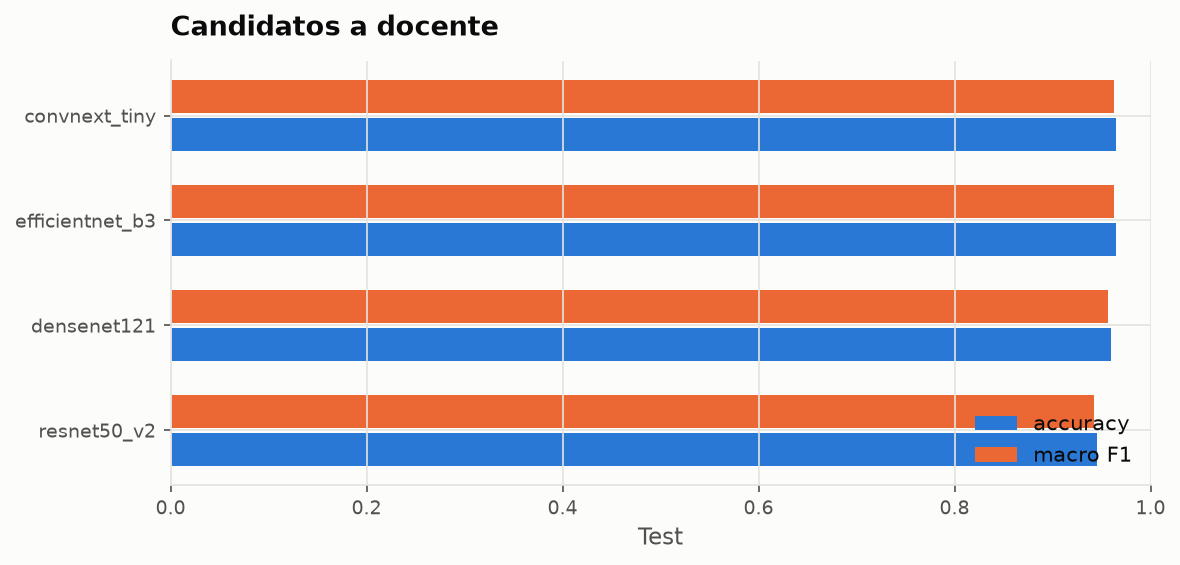

In [5]:
applyStyle()
import matplotlib.pyplot as plt

orden = comparacion.sort_values("validate_macro_f1")
y = range(len(orden))

fig, ax = plt.subplots(figsize=(8, 0.6 * len(orden) + 1.5))
ax.barh([i - 0.18 for i in y], orden["test_accuracy"], height=0.32, color=SERIE_1, label="accuracy")
ax.barh([i + 0.18 for i in y], orden["test_macro_f1"], height=0.32, color=SERIE_2, label="macro F1")
ax.set_yticks(list(y), orden["arquitectura"])
ax.set(xlim=(0, 1), xlabel="Test", title="Candidatos a docente")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## 3 · Docente elegido

Se deja en `teacher.json`
para que las notebooks de destilación lo lean sin elegirlo a mano.

In [6]:
limite = COSTO_MAX * comparacion["min_por_epoca"].min()
asequibles = comparacion[comparacion["min_por_epoca"] <= limite]
mejor = asequibles.sort_values("validate_macro_f1", ascending=False).iloc[0]
run = runPorArquitectura[(mejor["arquitectura"], mejor["descongelado"])]

registro.writeJson(registro.OUTPUTS_DIR / "teacher.json", {
    "run_id": run["run_id"],
    "architecture": mejor["arquitectura"],
    "dataset": CORPUS,
    "test_accuracy": float(mejor["test_accuracy"]),
    "test_macro_f1": float(mejor["test_macro_f1"]),
    "validate_macro_f1": float(mejor["validate_macro_f1"]),
    "latencia_ms": float(mejor["latencia_ms"]),
    "latencia_sd_ms": float(mejor["latencia_sd_ms"]),
    "parametros_M": float(mejor["parametros_M"]),
})

masPreciso = comparacion.iloc[0]
print(f"Docente: {mejor['arquitectura']} · macro-F1 {mejor['test_macro_f1']:.4f} · "
      f"{mejor['min_por_epoca']} min/época")
print(f"Hasta {limite:.1f} min/época: {', '.join(asequibles['arquitectura'])}")
if masPreciso["arquitectura"] != mejor["arquitectura"]:
    print(f"Cede {masPreciso['validate_macro_f1'] - mejor['validate_macro_f1']:.4f} de macro-F1 "
          f"en validación frente a {masPreciso['arquitectura']}, que tarda "
          f"{masPreciso['min_por_epoca'] / mejor['min_por_epoca']:.1f}x más por época")

estudiante = registro.readJson(registro.OUTPUTS_DIR / "student.json")
if estudiante:
    brecha = mejor["test_macro_f1"] - estudiante["test_macro_f1"]
    if estudiante["run_id"] == run["run_id"]:
        print(f"\nel mismo run gana ambos roles: destilar no aplica")
    elif brecha <= 0:
        print(f"\nel estudiante {estudiante['architecture']} supera a este docente por "
              f"{-brecha:+.4f}: destilar no tiene margen")
    else:
        print(f"\nbrecha con el estudiante {estudiante['architecture']}: {brecha:+.4f}")

from pathlib import Path

from scripts.kaggle import publicarArchivos
if Path("/kaggle").exists():
    publicarArchivos(f"Select {mejor['arquitectura']} as teacher",
                     "outputs/teacher.json")

Docente: efficientnet_b3 · macro-F1 0.9623 · 4.1 min/época
Hasta 6.2 min/época: efficientnet_b3, densenet121, resnet50_v2
Cede 0.0056 de macro-F1 en validación frente a convnext_tiny, que tarda 3.0x más por época

brecha con el estudiante mobilenet_v2: +0.0325


## Resumen

In [7]:
comparacion

,arquitectura,descongelado,test_accuracy,test_macro_f1,validate_macro_f1,parametros_M,tamano_MB,latencia_ms,latencia_sd_ms,minutos_entrenamiento,min_por_epoca,run_id
0,convnext_tiny,0.3,0.965125,0.962738,0.968718,28.39,266.4,750.1,35.6,373.1,12.4,20261017T232037Z_convnext-tiny
1,efficientnet_b3,0.3,0.964758,0.962312,0.963115,11.74,122.8,518.9,7.9,95.3,4.1,20261017T220206Z_efficientnet-b3
2,densenet121,0.3,0.959251,0.956820,0.959546,7.73,60.9,514.3,5.1,154.2,3.4,20261018T142451Z_densenet121
3,resnet50_v2,0.3,0.945668,0.941845,0.942867,24.79,247.1,305.6,2.8,92.9,3.1,20261018T055549Z_resnet50-v2
